<h1 align="center">Practice 3. Data Transformation & EDA: Pandas GroupBy, joins, reshaping (pivot/melt) + Matplotlib/Seaborn plots.</h1>

### Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Task 1. GroupBy

Use a dataset containing numerical and categorical variables. Group the data by one categorical 
column and calculate several aggregate statistics. Then group the data by two categorical columns 
and create a summary table using multiple aggregation functions.

In [2]:
df = pd.read_csv("./archive/car_details_v3.csv")

In [3]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


### Data clearing

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 825.6 KB


In [5]:
df = df.drop(columns=['torque', 'seats'])

In [6]:
df = df.dropna()

#### Changing types and normalization

In [7]:
km_kg_to_kmpl = {
    'LPG': 0.54,
    'CNG': 0.72,
}
def parse_mileage(row: pd.Series) -> str:
    # if (pd.isna(row['mileage'])):
    #     return row
    if row['mileage'].endswith(' km/kg'):
        value = float(row['mileage'].rstrip(' km/kg'))
        value *= km_kg_to_kmpl[row['fuel']]
    else:
        value = row['mileage'].rstrip(' kmpl') 
    row['mileage'] = value
    return row

In [8]:
df = df.apply(parse_mileage, axis=1)
df['mileage'] = df['mileage'].astype('float64')

In [9]:
def parse_engine(engine: str):
    return engine.rstrip(" C")

In [10]:
df['engine'] = df['engine'].apply(parse_engine).astype('int64')

In [11]:
categories = ['fuel', 'seller_type', 'transmission', 'owner']
for category in categories:
    df[category] = df[category].astype('category')

In [12]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248,74 bhp
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498,103.52 bhp
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497,78 bhp
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396,90 bhp
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298,88.2 bhp


In [13]:
df.info()

<class 'pandas.DataFrame'>
Index: 7907 entries, 0 to 8127
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   name           7907 non-null   str     
 1   year           7907 non-null   int64   
 2   selling_price  7907 non-null   int64   
 3   km_driven      7907 non-null   int64   
 4   fuel           7907 non-null   category
 5   seller_type    7907 non-null   category
 6   transmission   7907 non-null   category
 7   owner          7907 non-null   category
 8   mileage        7907 non-null   float64 
 9   engine         7907 non-null   int64   
 10  max_power      7907 non-null   str     
dtypes: category(4), float64(1), int64(4), str(2)
memory usage: 525.2 KB


### Grouping by fuel

In [14]:
df.groupby(by="fuel")[["km_driven", "selling_price"]].agg([
    'mean', 'max', 'min'
])

km_driven                  selling_price                 
                mean      max    min           mean       max    min
fuel                                                                
CNG     66050.396226   270000      1  313415.037736    545000  80000
Diesel  83319.920214  1500000   1000  802450.282624   7200000  45000
LPG     88856.685714   300000  30000  210885.714286    375000  54000
Petrol  51790.497727  2360457   1000  472665.203125  10000000  29999

### Grouping by fuel and transmission

In [15]:
df.groupby(by=['fuel', 'transmission'])['selling_price'].agg(
    ['mean', 'count', 'max', 'min']
)

mean  count       max     min
fuel   transmission                                       
CNG    Manual        3.134150e+05     53    545000   80000
Diesel Automatic     2.545534e+06    532   7200000  245000
       Manual        5.562808e+05   3767   3200000   45000
LPG    Manual        2.108857e+05     35    375000   54000
Petrol Automatic     1.190471e+06    509  10000000   75000
       Manual        3.513223e+05   3011   1520000   29999

## Task 2. Joins

Create a second DataFrame with a common key column. Combine the two DataFrames using merge() or join(). Perform inner and left joins and compare the resulting DataFrames.

In [16]:
df_additional = pd.read_csv("./archive/car_details_v3.csv", usecols=['name', 'torque', 'seats'])

In [17]:
df_additional.head()

,name,torque,seats
0,Maruti Swift Dzire VDI,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,"11.5@ 4,500(kgm@ rpm)",5.0


In [18]:
df.info()

<class 'pandas.DataFrame'>
Index: 7907 entries, 0 to 8127
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   name           7907 non-null   str     
 1   year           7907 non-null   int64   
 2   selling_price  7907 non-null   int64   
 3   km_driven      7907 non-null   int64   
 4   fuel           7907 non-null   category
 5   seller_type    7907 non-null   category
 6   transmission   7907 non-null   category
 7   owner          7907 non-null   category
 8   mileage        7907 non-null   float64 
 9   engine         7907 non-null   int64   
 10  max_power      7907 non-null   str     
dtypes: category(4), float64(1), int64(4), str(2)
memory usage: 525.2 KB


There are no unique column (identifier), so I use join method

In [19]:
df_merged_left = df.join(df_additional, lsuffix='_caller', rsuffix='_other')

In [20]:
df_merged_left.head()

,name_caller,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,name_other,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248,74 bhp,Maruti Swift Dzire VDI,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498,103.52 bhp,Skoda Rapid 1.5 TDI Ambition,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497,78 bhp,Honda City 2017-2020 EXi,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396,90 bhp,Hyundai i20 Sportz Diesel,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298,88.2 bhp,Maruti Swift VXI BSIII,"11.5@ 4,500(kgm@ rpm)",5.0


In [21]:
df_merged_left.shape

(7907, 14)

In [22]:
df_merged_inner = df.join(df_additional, lsuffix='_caller', rsuffix='_other', how="inner")

In [23]:
df_merged_right = df.join(df_additional, lsuffix='_caller', rsuffix='_other', how="right")

In [24]:
df_merged_left.equals(df_merged_right)

False

In [25]:
df_merged_left.shape

(7907, 14)

In [26]:
df_merged_right.shape

(8128, 14)

In [27]:
df_merged_right.iloc[200:206]

,name_caller,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,name_other,torque,seats
200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Toyota Etios GD,NaN,NaN
201,Honda City i VTEC S,2015.0,600000.0,50000.0,Petrol,Individual,Manual,First Owner,17.400,1497.0,117.3 bhp,Honda City i VTEC S,145Nm@ 4600rpm,5.0
202,Honda Brio S MT,2014.0,290000.0,60000.0,Petrol,Individual,Manual,Second Owner,19.400,1198.0,86.8 bhp,Honda Brio S MT,109Nm@ 4500rpm,5.0
203,Maruti Wagon R LXI CNG,2016.0,360000.0,50000.0,CNG,Individual,Manual,First Owner,19.152,998.0,58.16 bhp,Maruti Wagon R LXI CNG,77Nm@ 3500rpm,5.0
204,Maruti Swift Dzire VXI,2017.0,550000.0,50000.0,Petrol,Individual,Manual,First Owner,20.850,1197.0,83.14 bhp,Maruti Swift Dzire VXI,115Nm@ 4000rpm,5.0
205,Hyundai i20 Sportz 1.2,2013.0,375000.0,70000.0,Petrol,Individual,Manual,First Owner,18.500,1197.0,82.85 bhp,Hyundai i20 Sportz 1.2,113.7Nm@ 4000rpm,5.0


In [28]:
df_merged_inner.shape

(7907, 14)

If there were null values, left and right joins would have number of rows present in corresponding left and right DataFrames. Inner join holds not null values (rows) from both DataFrames. 
As I didn't delete null containing rows from df_additional, performing right join saved those values, providing null to all columns from df.

## Task 3. Reshaping

Create a pivot_table() using suitable categorical and numerical columns. Then reshape part of the dataset from wide to long format using melt(). Display the transformed DataFrames.

In [29]:
pivot_table = df.pivot_table(index='year', columns='fuel', values='selling_price', aggfunc="mean")
pivot_table

fuel,CNG,Diesel,LPG,Petrol
year,,,,
1994,NaN,9.900000e+04,NaN,4.500000e+04
1995,NaN,NaN,NaN,5.500000e+04
1996,NaN,NaN,NaN,4.100000e+04
1997,NaN,NaN,NaN,8.611100e+04
1998,NaN,NaN,NaN,5.788889e+04
1999,NaN,1.516667e+05,NaN,5.654545e+04
2000,80000.000000,1.066667e+05,NaN,6.890950e+04
2001,NaN,NaN,NaN,4.650000e+04
2002,NaN,1.486663e+05,NaN,9.537500e+04


In [30]:
pivot_table.reset_index().melt(id_vars=['year'], var_name='fuel' ,value_name='selling_price_avg').dropna().head()

,year,fuel,selling_price_avg
6,2000,CNG,80000.000000
14,2008,CNG,120000.000000
16,2010,CNG,188333.333333
17,2011,CNG,198500.000000
18,2012,CNG,221400.000000


In [31]:
df[df['fuel'] == 'CNG'][['year', 'fuel', 'selling_price']].groupby(by='year')[['year', 'fuel', 'selling_price']].agg(
    selling_price_avg = ('selling_price', 'mean')
).head()

,selling_price_avg
year,
2000,80000.000000
2008,120000.000000
2010,188333.333333
2011,198500.000000
2012,221400.000000


## Task 4. Visualization

Create at least four plots using Matplotlib and Seaborn:
- distribution of a numerical variable;
- comparison of categories;
- relationship between two numerical variables;
- comparison of a numerical variable across categories.
  
Add titles and axis labels to all plots.

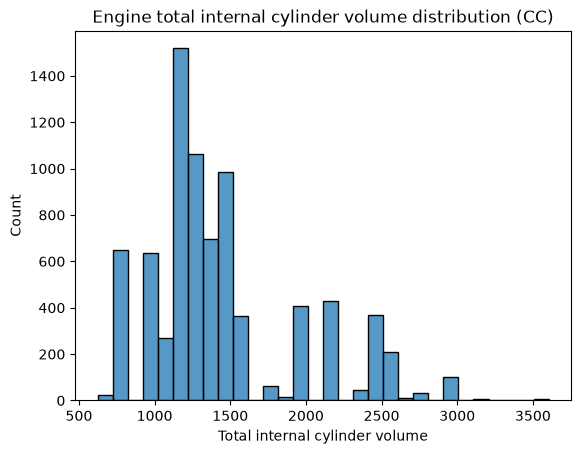

In [32]:
sns.histplot(df['engine'], binwidth=100)
plt.title('Engine total internal cylinder volume distribution (CC)')
plt.xlabel('Total internal cylinder volume')
plt.show()

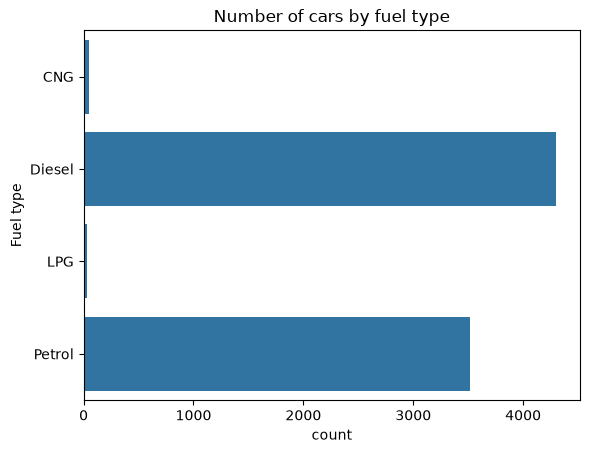

In [33]:
sns.countplot(df['fuel']);
plt.title('Number of cars by fuel type')
plt.ylabel('Fuel type')
plt.show()

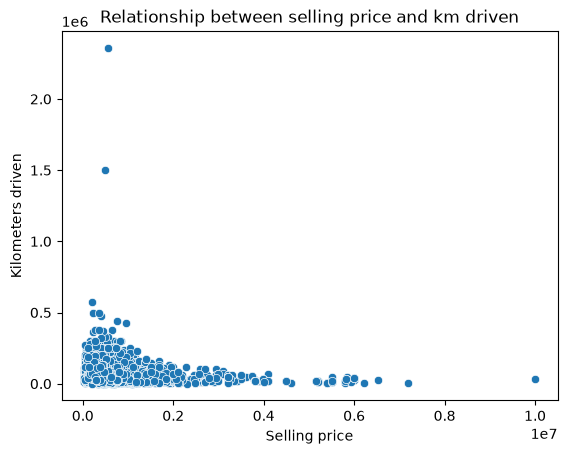

In [34]:
sns.scatterplot(df, x='selling_price', y='km_driven')
plt.title('Relationship between selling price and km driven')
plt.xlabel('Selling price')
plt.ylabel('Kilometers driven')
plt.show()

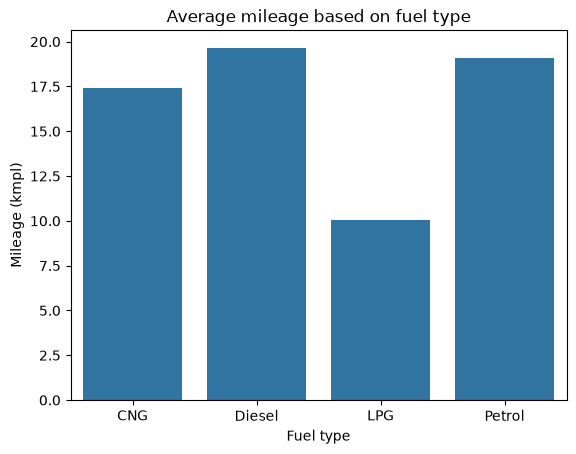

In [35]:
sns.barplot(df, x='fuel', y='mileage', estimator='mean', errorbar=None)
plt.title('Average mileage based on fuel type')
plt.xlabel('Fuel type')
plt.ylabel("Mileage (kmpl)")
plt.show()

## Task 5. EDA

Perform an exploratory analysis using grouped statistics and visualizations. Compare categories, identify patterns in numerical variables, and examine relationships between selected features. Write five findings supported by the calculated results and plots.

### 1. Average selling price by fuel

In [36]:
df.groupby('fuel')['selling_price'].agg(['mean', 'median', 'count'])

,mean,median,count
fuel,,,
CNG,313415.037736,330000.0,53
Diesel,802450.282624,550000.0,4299
LPG,210885.714286,200000.0,35
Petrol,472665.203125,350000.0,3520


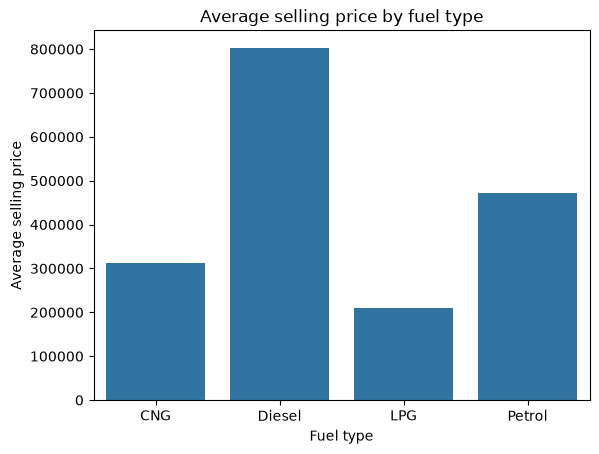

In [37]:
sns.barplot(df, x='fuel', y='selling_price', estimator='mean', errorbar=None
)
plt.title('Average selling price by fuel type')
plt.xlabel('Fuel type')
plt.ylabel('Average selling price')
plt.show()

#### Finding

The average selling price differs between fuel types. Among 4 fuel types, diesel has the highest average selling price and LPG the lowest.

### 2. Mileage accross fuel types

[Visualization](#Task-4.-Visualization)

#### Finding

Diesel has the best mileage in kilometers per liter of fuel.

### 3. Selling price vs kilometers driven

[Visualization](#Task-4.-Visualization)

In [38]:
df[['selling_price', 'km_driven']].corr()

,selling_price,km_driven
selling_price,1.000000,-0.222196
km_driven,-0.222196,1.000000


#### Finding 

There is a weak negative correlation between kilometers driven and car selling price. This mean the more kilometers were traveled, the chepear selling price is.

### 4. Selling price accross years

In [39]:
df.groupby(by='year').agg(
    selling_price_avg = ('selling_price', 'mean'),
    selling_price_median = ('selling_price', 'median'),
    selling_price_count = ('selling_price', 'count')
)

,selling_price_avg,selling_price_median,selling_price_count
year,,,
1994,7.200000e+04,72000.0,2
1995,5.500000e+04,55000.0,1
1996,4.100000e+04,41000.0,2
1997,8.611100e+04,50000.0,9
1998,5.788889e+04,58000.0,9
1999,7.692857e+04,62500.0,14
2000,7.668212e+04,77500.0,16
2001,4.650000e+04,45000.0,6
2002,1.037894e+05,75000.0,19


#### Finding

1. The largest number of cars was sold in 2017 — 1,010
2. The highest median price occured in 2019
3. The highest average price occured in 2019

### 5. Sales count depending on the transmission

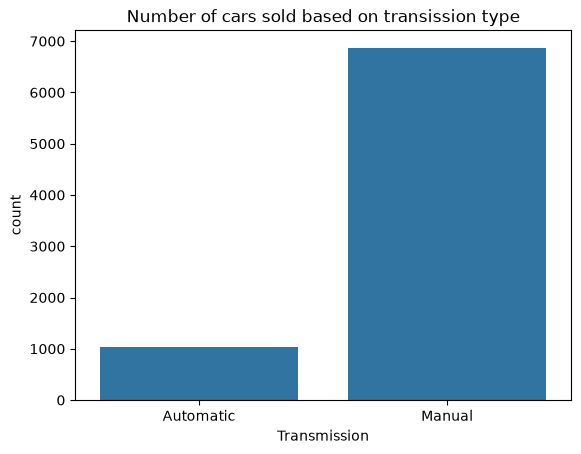

In [40]:
sns.countplot(df, x='transmission')

plt.title('Number of cars sold based on transission type')
plt.xlabel('Transmission')
plt.show()

#### Finding

Manual transission is far more popular than Automatic.